# NB08 · Structured assets

**Project:** multiyear-credit-engine
**Job requirement covered:** Structured assets; asset and risk characteristics.
**Engine module:** `creditengine.assets.structured`
**Assumptions:** A-08, A-15
**Theory:** Bluhm §8.1, §8.3, §8.6
**Status:** ✅ Developed — every function is built from scratch in this notebook

## Objective

How does a slice of a loan pool lose money — how attachment and detachment turn the pool's loss into each tranche's loss, why a senior tranche is quiet in normal years but loses in the joint tail, how correlation moves risk between tranches, and how its statutory capital compares with the tail capital it really uses?

## Results at a glance

| Question | Answer |
|---|---|
| How much does the pool lose? | Five-year loss **7.8%** on average; 23.2% in a 1-in-200 path |
| How does that reach the tranches? | Equity loses 57% on average; BB 8.1%; BBB 2.5%; A 0.6%; AA 0.09%; AAA essentially nothing |
| What is special about senior tranches? | **Cliff risk:** the A tranche loses something in only 1.2% of paths, but in the worst 0.5% it loses **88%** — ES is 142 times EL |
| What does correlation do? | Same pool, same average loss: raising ρ from 15% to 25% cuts equity EL 5% but multiplies the A tranche's EL by **3.7** and the AA tranche's by 7.6 |
| Statutory vs economic capital | The held A tranche (USD 20m) is 29% of the stack's RBC but **70% of its tail capital** — 86 times its RBC |
| Does the engine work? | Tranche losses add back to the pool on every path; simulated tranche EL matches the large-pool formula (e.g. 3.09% vs 3.03% on [3%, 7%]) |

## Key terms and symbols

| Term | Meaning |
|---|---|
| **Pool** | 200 leveraged loans (BB, B, CCC), the collateral of a CLO-like structure |
| $L$ | Pool loss rate: share of the pool's notional lost to defaults over five years |
| **Tranche** $[a, d]$ | A slice of the pool's losses between attachment $a$ and detachment $d$ |
| $a$ (attachment) | Pool loss at which the tranche starts to lose = subordination below it |
| $d$ (detachment) | Pool loss at which the tranche is wiped out |
| $d - a$ (thickness) | Size of the tranche as a share of the pool |
| **Equity** | First-loss tranche $[0, a_1]$; **senior** tranches sit on top |
| $\rho$ | Asset correlation of the pool's loans (0.15) |
| **NAIC designation** | Statutory grade used for the tranche's capital factor, fixed at issue (A-15) |

## Inputs

| Data | File | Used for |
|---|---|---|
| Pool and tranche settings (A-08, A-15) | settings of `configs/portfolios/structured.yaml`, declared in section 0 | the structure |
| Matrix and thresholds (NB01, NB04) | `data/processed/` | pool loan migrations and defaults |
| S&P cumulative default rates (local only) | `data/external/cumulative_default_rates.csv` | five-year pool PD for the closed form |
| NAIC C-1 factors (NB01) | `data/external/naic_bond_factors.csv` | tranche capital |

NAIC is moving towards dedicated CLO tranche factors; until those are final the tranche is charged as a bond of its designation (A-15).

## Outputs

- `data/processed/sim_tranche_losses.parquet` — five-year loss of each tranche on every path
- `reports/figures/tranche_payoff.png` — pool loss distribution with the attachment points, and each tranche's payoff
- `reports/figures/tranche_correlation_sensitivity.png` — tranche expected loss against pool correlation

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, EXTERNAL = ROOT / "data", ROOT / "data" / "external"
RATINGS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC/C"]
STATES, D = RATINGS + ["D"], 7
pd.set_option("display.float_format", "{:,.3f}".format)

M = pd.read_parquet(DATA / "processed" / "transition_matrix_1y.parquet").loc[STATES, STATES]
C = pd.read_parquet(DATA / "processed" / "migration_thresholds.parquet").loc[STATES, STATES].to_numpy()

POOL = {"n": 200, "mix": {"BB": 0.30, "B": 0.65, "CCC/C": 0.05}, "rho": 0.15,
        "lgd_mean": 0.40, "lgd_sd": 0.25,                 # senior secured loans (A-04)
        "years": 5, "paths": 20_000, "phi": 0.5, "seed": 2026}
TRANCHES = pd.DataFrame([("equity", 0.00, 0.13, "6"), ("BB", 0.13, 0.17, "3.B"), ("BBB", 0.17, 0.21, "2.B"),
                         ("A", 0.21, 0.25, "1.F"), ("AA", 0.25, 0.30, "1.C"), ("AAA", 0.30, 1.00, "1.A")],
                        columns=["tranche", "attach", "detach", "designation"]).set_index("tranche")
TRANCHES["thickness"] = TRANCHES["detach"] - TRANCHES["attach"]
HELD = {"AAA": 100e6, "AA": 40e6, "A": 20e6}              # the insurer holds the senior part (A-15)
TRANCHES

,attach,detach,designation,thickness
tranche,,,,
equity,0.000,0.130,6,0.130
BB,0.130,0.170,3.B,0.040
BBB,0.170,0.210,2.B,0.040
A,0.210,0.250,1.F,0.040
AA,0.250,0.300,1.C,0.050
AAA,0.300,1.000,1.A,0.700


## 1. Pool loss distribution

The pool is simulated with the same engine as the bond book (NB06): each year a shared cycle $Z_t$, each loan's asset return $A_{i,t} = \sqrt{\rho} Z_t + \sqrt{1-\rho} \varepsilon_{i,t}$, migration through the NB04 thresholds, and a beta LGD (mean 40%) on default. Loans are equal-sized and outlive the five-year horizon.

$$L = \frac{1}{N}\sum_{i=1}^{N} \sum_{t=1}^{5} \mathbf{1}\{\text{loan } i \text{ defaults in year } t\} \times LGD_{i,t}$$

The pool's cumulative loss rate over five years, as a share of its starting notional.

In [2]:
def cycle_paths(n_paths, years, phi, rng):
    z, z_prev = np.empty((n_paths, years)), rng.standard_normal(n_paths)
    for t in range(years):
        z[:, t] = phi * z_prev + np.sqrt(1 - phi**2) * rng.standard_normal(n_paths)
        z_prev = z[:, t]
    return z

def migrate(state, A, C):
    new = state.copy()
    for r in range(7):
        m = state == r
        new[m] = 7 - np.searchsorted(C[r, 7:0:-1], A[m], side="left")
    return new

def simulate_pool(p, rho=None, seed=None):
    rho = p["rho"] if rho is None else rho
    rng = np.random.default_rng(p["seed"] if seed is None else seed)
    rating = np.repeat([RATINGS.index(r) for r in p["mix"]], [round(w * p["n"]) for w in p["mix"].values()])
    k = p["lgd_mean"] * (1 - p["lgd_mean"]) / p["lgd_sd"]**2 - 1
    z = cycle_paths(p["paths"], p["years"], p["phi"], rng)
    state = np.tile(rating, (p["paths"], 1))
    loss = np.zeros(p["paths"])
    for t in range(p["years"]):
        alive = state != D
        A = np.sqrt(rho) * z[:, t:t + 1] + np.sqrt(1 - rho) * rng.standard_normal(state.shape)
        new = np.where(alive, migrate(state, A, C), state)
        lgd = rng.beta(p["lgd_mean"] * k, (1 - p["lgd_mean"]) * k, size=state.shape)
        loss += ((alive & (new == D)) * lgd).sum(axis=1) / len(rating)
        state = new
    return loss, z

pool_loss, Z = simulate_pool(POOL)
qs = [0.5, 0.9, 0.99, 0.995, 0.999]
pd.Series({"mean": pool_loss.mean(), **{f"{q:.1%} quantile": np.quantile(pool_loss, q) for q in qs}}, name="pool loss rate %").mul(100).to_frame().T

,mean,50.0% quantile,90.0% quantile,99.0% quantile,99.5% quantile,99.9% quantile
pool loss rate %,7.847,7.020,14.107,21.493,23.172,26.926


**Reading the result:** the pool of leveraged loans loses 7.8% of its notional over five years on average, 14% in a 1-in-10 path and 23% in a 1-in-200 path. The distribution is strongly skewed: the shared cycle makes many loans default together in bad paths. That skew is what the tranches slice up.

## 2. Tranche loss: attachment, detachment, thickness

$$TL_{[a,d]}(L) = \frac{(L - a)^+ - (L - d)^+}{d - a}$$

The tranche loses nothing while the pool loses less than $a$; between $a$ and $d$ every extra point of pool loss eats into it; above $d$ it is wiped out. Dividing by the thickness expresses the loss as a share of the tranche's own notional.

*Example:* A tranche [21%, 25%], pool loss 23% → (23 − 21) / (25 − 21) = 50% of the tranche lost.

$$\sum_{\text{tranches}} (d - a) \times TL_{[a,d]}(L) = L$$

If the tranches tile $[0, 1]$, their losses add back to exactly the pool's loss — nothing created, nothing lost (V-10).

In [3]:
def tranche_loss(pool, attach, detach):
    pool = np.asarray(pool, dtype=float)
    return (np.maximum(pool - attach, 0) - np.maximum(pool - detach, 0)) / (detach - attach)

example = pd.DataFrame({name: [100 * tranche_loss(L_, r.attach, r.detach) for L_ in [0.05, 0.13, 0.15, 0.19, 0.23, 0.28, 0.40]]
                        for name, r in TRANCHES.iterrows()}, index=[f"pool loss {L_:.0%}" for L_ in [0.05, 0.13, 0.15, 0.19, 0.23, 0.28, 0.40]])
example

,equity,BB,BBB,A,AA,AAA
pool loss 5%,38.462,0.000,0.000,0.000,0.000,0.000
pool loss 13%,100.000,0.000,0.000,0.000,0.000,0.000
pool loss 15%,100.000,50.000,0.000,0.000,0.000,0.000
pool loss 19%,100.000,100.000,50.000,0.000,0.000,0.000
pool loss 23%,100.000,100.000,100.000,50.000,0.000,0.000
pool loss 28%,100.000,100.000,100.000,100.000,60.000,0.000
pool loss 40%,100.000,100.000,100.000,100.000,100.000,14.286


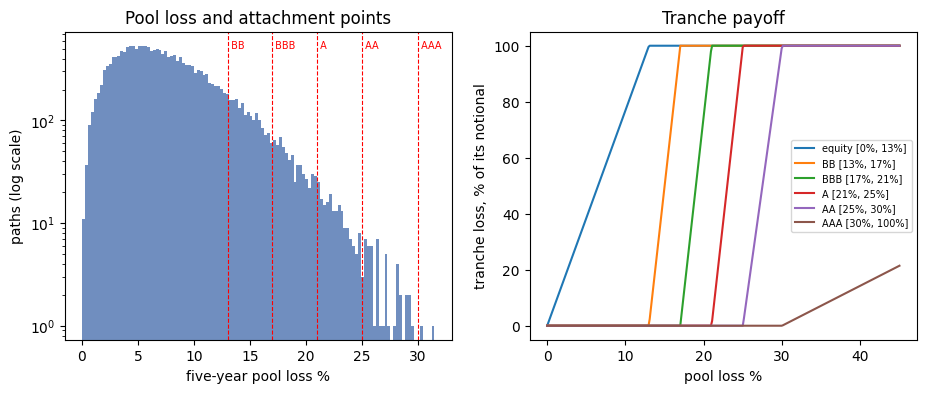

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(100 * pool_loss, bins=120, color="#4C72B0", alpha=0.8)
for name, r in TRANCHES.iterrows():
    if r.attach > 0:
        axes[0].axvline(100 * r.attach, color="red", lw=0.8, ls="--")
        axes[0].text(100 * r.attach, axes[0].get_ylim()[1] * 0.9, f" {name}", fontsize=7, color="red")
axes[0].set_yscale("log")
axes[0].set(xlabel="five-year pool loss %", ylabel="paths (log scale)", title="Pool loss and attachment points")
grid = np.linspace(0, 0.45, 300)
for name, r in TRANCHES.iterrows():
    axes[1].plot(100 * grid, 100 * tranche_loss(grid, r.attach, r.detach), label=f"{name} [{r.attach:.0%}, {r.detach:.0%}]")
axes[1].set(xlabel="pool loss %", ylabel="tranche loss, % of its notional", title="Tranche payoff")
axes[1].legend(fontsize=7)
fig.savefig(ROOT / "reports" / "figures" / "tranche_payoff.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Tranche expected loss and tail loss

For each tranche, on the 20,000 simulated pools: expected loss, the probability of losing anything, and the expected shortfall at 99.5% — all as a share of the tranche's notional. Then the same in USD for the tranches the insurer holds.

For comparison, a **corporate bond** of the same rating loses $PD_5$ × 60% over five years on average (S&P five-year cumulative PD, NB01).

In [5]:
TL = pd.DataFrame({name: tranche_loss(pool_loss, r.attach, r.detach) for name, r in TRANCHES.iterrows()})
tail = pool_loss >= np.quantile(pool_loss, 0.995)
cum5 = pd.read_csv(EXTERNAL / "cumulative_default_rates.csv", index_col=0)["5"] / 100
summary = pd.DataFrame({"attach %": 100 * TRANCHES["attach"], "EL %": 100 * TL.mean(), "P(any loss) %": 100 * (TL > 0).mean(),
                        "ES 99.5% %": 100 * TL[tail].mean()})
summary["ES / EL"] = summary["ES 99.5% %"] / summary["EL %"]
summary["corporate bond, same rating: 5-yr EL %"] = [np.nan] + [100 * cum5[r] * 0.60 for r in ["BB", "BBB", "A", "AA", "AAA"]]
summary

,attach %,EL %,P(any loss) %,ES 99.5% %,ES / EL,"corporate bond, same rating: 5-yr EL %"
equity,0.000,56.868,100.000,100.000,1.758,NaN
BB,13.000,8.128,13.330,100.000,12.303,3.354
BBB,17.000,2.495,4.350,100.000,40.080,0.798
A,21.000,0.618,1.205,87.984,142.262,0.228
AA,25.000,0.092,0.245,18.415,200.000,0.162
AAA,30.000,0.000,0.010,0.025,200.000,0.204


**Reading the result:** risk is concentrated at the bottom and the cliff sits in the middle. The equity tranche always loses something (57% on average). The A tranche loses something in only 1.2% of paths — but when it does, it is usually most of it: in the worst 0.5% of paths it loses 88% of its notional, 142 times its expected loss. A corporate A bond spreads its risk over many independent outcomes; a senior tranche concentrates it into one state of the world. The comparison column also shows that a tranche is not a bond: the BBB tranche's five-year EL (2.5%) is three times a BBB corporate's (0.8%) here, because the tranche labels follow the position in this stylised structure, not an agency rating.

### 3.1 Check against the large-pool closed form

For a very large one-period pool with one PD and a fixed LGD, the pool loss given $Z$ is $LGD \times PD(Z)$, so a tranche's expected loss is a one-dimensional integral:

$$\mathbb{E}\big[TL_{[a,d]}\big] = \int TL_{[a,d]}\big(LGD \times PD(z)\big) \varphi(z) dz, \qquad PD(z) = \Phi\left(\frac{\Phi^{-1}(PD) - \sqrt{\rho} z}{\sqrt{1-\rho}}\right)$$

Test case: 1,000 single-B loans, one year, $\rho$ = 0.15, LGD 40%, 20,000 simulated years, tranches cut at 0 / 1 / 2 / 3 / 7 / 100%.

In [6]:
def large_pool_el(pd_, rho, lgd, attach, detach):
    z = np.linspace(-8, 8, 4001)
    w = norm.pdf(z) / norm.pdf(z).sum()
    pool = lgd * norm.cdf((norm.ppf(pd_) - np.sqrt(rho) * z) / np.sqrt(1 - rho))
    return float((tranche_loss(pool, attach, detach) * w).sum())

p_B = M.loc["B", "D"]
rng = np.random.default_rng(11)
one_year = np.empty(20_000)
for chunk in np.array_split(np.arange(20_000), 4):
    zc = rng.standard_normal((chunk.size, 1))
    A = np.sqrt(0.15) * zc + np.sqrt(0.85) * rng.standard_normal((chunk.size, 1_000))
    one_year[chunk] = 0.40 * (A <= C[RATINGS.index("B"), D]).mean(axis=1)       # fixed LGD 40%
cuts = [(0.0, 0.01), (0.01, 0.02), (0.02, 0.03), (0.03, 0.07), (0.07, 1.0)]
closed = pd.DataFrame({f"[{a:.0%}, {d:.0%}]": {"simulated EL %": 100 * tranche_loss(one_year, a, d).mean(),
                                                "closed form EL %": 100 * large_pool_el(p_B, 0.15, 0.40, a, d)} for a, d in cuts}).T
closed["relative difference %"] = 100 * (closed["simulated EL %"] / closed["closed form EL %"] - 1)
closed

,simulated EL %,closed form EL %,relative difference %
"[0%, 1%]",71.976,73.063,-1.488
"[1%, 2%]",30.878,31.333,-1.454
"[2%, 3%]",13.901,13.924,-0.166
"[3%, 7%]",3.086,3.029,1.891
"[7%, 100%]",0.011,0.010,11.852


## 4. Sensitivity of tranches to correlation

Same pool, same average loss — only the correlation $\rho$ between loans changes. Large-pool closed form over the five-year horizon (pool PD = five-year cumulative PD of the BB/B/CCC mix, LGD 40%), then a full-simulation check at $\rho$ = 0.25.

$$\text{pool EL} = PD_5 \times LGD \quad \text{(the same for every } \rho)$$

In [7]:
pool_pd5 = sum(w * cum5[r] for r, w in POOL["mix"].items())
rhos = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40]
sens = pd.DataFrame({f"rho {r:.0%}": {"pool EL": pool_pd5 * 0.40,
                                       **{name: large_pool_el(pool_pd5, r, 0.40, t_.attach, t_.detach) for name, t_ in TRANCHES.iterrows()}}
                     for r in rhos}).T * 100
print(f"five-year pool PD {pool_pd5:.2%}, pool EL {pool_pd5 * 0.40:.2%}  (EL in % of each tranche's notional)")
sens

five-year pool PD 13.96%, pool EL 5.58%  (EL in % of each tranche's notional)


,pool EL,equity,BB,BBB,A,AA,AAA
rho 5%,5.584,42.938,0.052,0.001,0.000,0.000,0.000
rho 10%,5.584,42.677,0.816,0.079,0.005,0.000,0.000
rho 15%,5.584,42.090,2.272,0.458,0.069,0.006,0.000
rho 20%,5.584,41.287,3.919,1.160,0.281,0.042,0.000
rho 30%,5.584,39.325,6.977,3.087,1.219,0.353,0.004
rho 40%,5.584,37.103,9.445,5.181,2.647,1.087,0.022


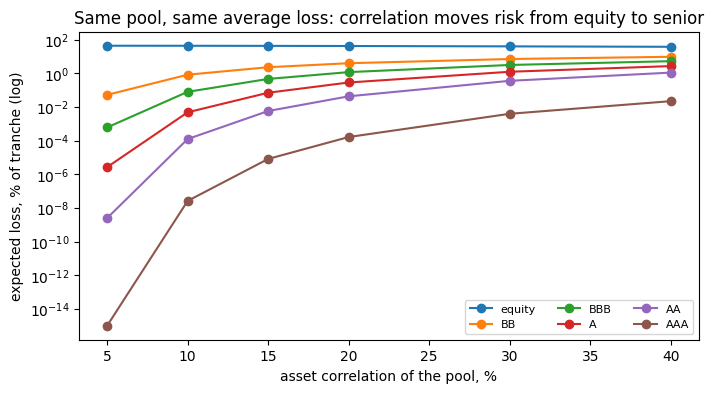

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in TRANCHES.index:
    ax.plot([100 * r for r in rhos], sens[name], marker="o", label=name)
ax.set_yscale("log")
ax.set(xlabel="asset correlation of the pool, %", ylabel="expected loss, % of tranche (log)",
       title="Same pool, same average loss: correlation moves risk from equity to senior")
ax.legend(fontsize=8, ncol=3)
fig.savefig(ROOT / "reports" / "figures" / "tranche_correlation_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
pool_hi, _ = simulate_pool(POOL, rho=0.25)
TL_hi = pd.DataFrame({name: tranche_loss(pool_hi, r.attach, r.detach) for name, r in TRANCHES.iterrows()})
pd.DataFrame({"rho 15%: EL %": 100 * TL.mean(), "rho 25%: EL %": 100 * TL_hi.mean(),
              "change %": 100 * (TL_hi.mean() / TL.mean() - 1)}).T.assign(pool=[100 * pool_loss.mean(), 100 * pool_hi.mean(),
                                                                                100 * (pool_hi.mean() / pool_loss.mean() - 1)])

,equity,BB,BBB,A,AA,AAA,pool
rho 15%: EL %,56.868,8.128,2.495,0.618,0.092,0.000,7.847
rho 25%: EL %,54.214,12.371,5.679,2.315,0.695,0.008,7.903
change %,-4.666,52.193,127.631,274.349,655.201,"6,012.421",0.706


**Reading the result:** correlation does not change the pool's average loss, but it changes **who** bears it. Higher correlation makes defaults cluster: more paths with few defaults (good for equity) and more paths with many (bad for seniors). In the closed form, moving from ρ = 5% to 40% lowers equity EL from 43% to 37% while the A tranche goes from zero to 2.6%. The full simulation confirms it: at ρ = 25% instead of 15%, the A tranche's EL rises 3.7 times and the AA tranche's 7.6 times while the pool loses only 0.7% more. The closed form is a one-period, fixed-LGD approximation of a five-year pool, so its levels differ from the simulation; it is used here for direction. A senior tranche is a short position on correlation — an assumption that is hard to estimate and that rating-based capital does not see.

## 5. Capital by tranche designation

**Statutory view:** a tranche is charged like a bond of its NAIC designation, fixed at issue:

$$\text{RBC} = f(\text{designation}) \times \text{held amount}$$

**Economic view:** the tranche's contribution to the tail of the held senior stack (AAA 100m, AA 40m, A 20m):

$$RC_j = \mathbb{E}\big[L_j \mid L_{\text{held}} \ge \text{VaR}_q\big] - \mathbb{E}[L_j], \qquad q = 0.995$$

If the two views disagree, rating-based capital is mispricing the tranche's real risk.

In [10]:
naic = pd.read_csv(EXTERNAL / "naic_bond_factors.csv", dtype={"naic_designation": str}).set_index("naic_designation")["factor_pct"] / 100
held = pd.Series(HELD)
L_held = TL[held.index].to_numpy() @ held.to_numpy()                    # USD loss of the held stack, per path
var_h = np.quantile(L_held, 0.995)
in_tail = L_held >= var_h
loss_usd = TL[held.index] * held                                       # USD loss per tranche, per path
rc = loss_usd[in_tail].mean() - loss_usd.mean()
cap = pd.DataFrame({"held USD m": held / 1e6, "designation": TRANCHES.loc[held.index, "designation"],
                    "RBC factor %": 100 * TRANCHES.loc[held.index, "designation"].map(naic).astype(float)})
cap["RBC USD m"] = cap["held USD m"] * cap["RBC factor %"] / 100
cap["EL 5y USD m"] = loss_usd.mean() / 1e6
cap["ES capital USD m"] = rc / 1e6
cap["share of RBC %"] = 100 * cap["RBC USD m"] / cap["RBC USD m"].sum()
cap["share of ES capital %"] = 100 * cap["ES capital USD m"] / cap["ES capital USD m"].sum()
cap["ES capital / RBC"] = cap["ES capital USD m"] / cap["RBC USD m"]
print(f"held stack: EL {L_held.mean() / 1e6:.2f}m, ES 99.5% {L_held[in_tail].mean() / 1e6:.1f}m, contributions sum {rc.sum() / 1e6:.1f}m = ES - EL")
cap

held stack: EL 0.16m, ES 99.5% 25.0m, contributions sum 24.8m = ES - EL


,held USD m,designation,RBC factor %,RBC USD m,EL 5y USD m,ES capital USD m,share of RBC %,share of ES capital %,ES capital / RBC
AAA,100.000,1.A,0.290,0.290,0.000,0.025,40.616,0.101,0.086
AA,40.000,1.C,0.550,0.220,0.037,7.329,30.812,29.520,33.314
A,20.000,1.F,1.020,0.204,0.124,17.473,28.571,70.379,85.653


**Reading the result:** the statutory and economic views disagree sharply. By RBC the three held tranches look alike (USD 0.2–0.3m each). By tail capital the A tranche uses 70% of the stack's ES capital (USD 17.5m, 86 times its RBC) and the AA tranche 30%, while the AAA tranche uses almost none. The held stack's EL is only USD 0.16m but its ES is USD 25m. This is the README finding — structured assets are 2% of expected loss but 25% of tail capital in the whole book — seen from inside the structure: the rating-based factor charges for the average, the tail sits in the thin mezzanine-senior slice.

## 6. Save outputs

In [11]:
(TL * 1).assign(pool=pool_loss).to_parquet(DATA / "processed" / "sim_tranche_losses.parquet")
print("saved", TL.shape)

saved (20000, 6)


## Validation checks

- [x] **Tranche losses sum to pool loss (V-10)** — the tranches tile [0, 1] and their losses, weighted by thickness, add back to the pool loss on every path.
- [x] **Monotone in attachment point** — expected loss, probability of loss and expected shortfall all fall as the attachment rises.
- [x] **Large-pool closed form** — simulated tranche expected loss within 5% of the integral for every tranche with a visible loss; the far-senior slice (EL about 0.01%) agrees within 0.005 points.
- [x] **Correlation moves risk, not the total** — pool EL is the same at every $\rho$; equity EL falls and AAA EL rises.

In [12]:
tiles = np.isclose(TRANCHES["attach"].iloc[0], 0) and np.isclose(TRANCHES["detach"].iloc[-1], 1) \
        and np.allclose(TRANCHES["detach"].to_numpy()[:-1], TRANCHES["attach"].to_numpy()[1:])
rebuilt = (TL * TRANCHES["thickness"]).sum(axis=1)
checks = {
    "V-10: tranches tile [0, 1] with no gap or overlap": bool(tiles),
    "V-10: thickness-weighted tranche losses = pool loss on every path": bool(np.allclose(rebuilt, pool_loss)),
    "EL decreases with attachment": bool(summary["EL %"].is_monotonic_decreasing),
    "P(any loss) decreases with attachment": bool(summary["P(any loss) %"].is_monotonic_decreasing),
    "ES decreases with attachment": bool(summary["ES 99.5% %"].is_monotonic_decreasing),
    "Large-pool closed form within 5% (or 0.005 points for near-zero tranches)": bool(
        ((closed["relative difference %"].abs() < 5) | ((closed["simulated EL %"] - closed["closed form EL %"]).abs() < 0.005)).all()),
    "Pool EL constant across rho; equity falls, AAA rises": bool(np.allclose(sens["pool EL"], sens["pool EL"].iloc[0])
                                                                 and sens["equity"].is_monotonic_decreasing and sens["AAA"].is_monotonic_increasing),
    "ES contributions sum to ES - EL of the held stack": bool(np.isclose(rc.sum(), L_held[in_tail].mean() - L_held.mean())),
}
pd.Series(checks).map({True: "PASS", False: "FAIL"})

V-10: tranches tile [0, 1] with no gap or overlap                            PASS
V-10: thickness-weighted tranche losses = pool loss on every path            PASS
EL decreases with attachment                                                 PASS
P(any loss) decreases with attachment                                        PASS
ES decreases with attachment                                                 PASS
Large-pool closed form within 5% (or 0.005 points for near-zero tranches)    PASS
Pool EL constant across rho; equity falls, AAA rises                         PASS
ES contributions sum to ES - EL of the held stack                            PASS
dtype: object

## Functions to move into the engine

| Function (this notebook) | Target module | Test |
|---|---|---|
| `tranche_loss` | `creditengine.assets.structured` | conservation (V-10); worked example |
| `simulate_pool` | `creditengine.assets.structured`, `simulation` | pool loss distribution |
| `large_pool_el` | `creditengine.assets.structured` | simulated vs closed form within 5% |
| correlation sensitivity | `creditengine.assets.structured` | pool EL constant; equity down, AAA up |
| tranche RBC vs ES capital | `creditengine.capital` | contributions sum to ES − EL |

## Findings and next steps

**Key results**
- **Pool:** five-year loss 7.8% on average, 23.2% at 99.5%.
- **Tranches:** equity 57% EL; A tranche 0.6% EL but 88% loss in the worst 0.5% of paths (ES / EL = 142) — cliff risk.
- **Correlation:** pool EL unchanged, but ρ 15% → 25% multiplies the A tranche's EL by 3.7 and the AA's by 7.6.
- **Capital:** the A tranche is 29% of the held stack's RBC but 70% of its ES capital (86 × RBC); held stack EL 0.16m, ES 25.0m — consistent with the whole-book run in the README (0.17m, 25.3m).
- **Validation:** tranche losses conserve the pool loss on every path; simulated tranche EL matches the large-pool formula.

**Assumptions** (record in `docs/assumption_register.md`)
- A-08 unchanged: 200-loan homogeneous pool (BB 30%, B 65%, CCC 5%), ρ = 0.15, LGD 40%; tranche loss = sequential loss allocation; attachments from pool-loss quantiles.
- A-15 unchanged: held AAA 100m, AA 40m, A 20m; NAIC designation fixed at issue; bond factors used for tranches.

**Limitations** (record in `docs/limitations.md`)
1. **Loss allocation, not cash flow:** no interest waterfall, no overcollateralisation or interest-coverage tests (L-09); real CLOs divert cash to seniors when tests fail, which protects them.
2. **Static pool:** no reinvestment, trading or manager behaviour.
3. **Designation fixed at issue (L-12):** in practice tranches are downgraded in a stress and their RBC rises.
4. **Correlation is an assumption:** senior tranche risk is highly sensitive to ρ, which public data barely pins down.
5. **Bond factors for tranches:** NAIC's dedicated CLO tranche factors are not yet applied.

**Next:** NB10 (model validation), then NB11 (assumptions, outputs and reporting).